In [16]:
%matplotlib inline
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
import shap
import matplotlib.pyplot as plt

In [2]:
# Load the dataset
try:
    df = pd.read_excel("../../../Datasets/excel/2dSpoofingDataset/GPS_Data_Simplified_2D_Feature_Map.xlsx")
except FileNotFoundError:
    print("Error: The file '../../../Datasets/excel/2dSpoofingDataset/GPS_Data_Simplified_2D_Feature_Map.xlsx' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [3]:
feature_names = list(df.columns)
print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   PRN           DO             PD         RX            TOW            CP  \
0    6  1160.671408 -238359.543282  491568.00  491568.000795 -24660.263293   
1    6  1157.827808 -238363.921192  491568.02  491568.020795 -24683.468520   
2    6  1161.135932 -238368.638615  491568.04  491568.040795 -24706.687357   
3    6  1161.156617 -238373.391775  491568.06  491568.060795 -24729.920039   
4    6  1160.690893 -238378.127066  491568.08  491568.080795 -24753.153999   

          EC         LC         PC        PIP          PQP        TCD  \
0  163521.78  170008.81  179294.97  178420.33 -17688.17800  1158.4806   
1  158277.05  160253.09  182106.11  182106.05    158.33333  1160.7948   
2  184442.36  193125.89  208228.02 -205198.30  35391.59000  1157.6909   
3  159812.45  169960.55  187550.72  187543.00  -1701.94400  1161.1343   
4  183557.66  191912.58  208403.50  208330.05  -5532.89990  1161.1759   

         CN0  Output  
0  49.412529       0  
1  49.452686     

In [4]:
feature_names.remove('Output')
X = df[feature_names]
y = df['Output']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=100
)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model on scaled data
clf = LogisticRegression()
clf.fit(X_train_scaled, y_train)

LogisticRegression()

Intercept 0.18130928864203813
Prediction_local [0.18569015]
Right: 0.018493254915714352
Intercept 0.07857955405328362
Prediction_local [0.00923507]
Right: 0.026462132740293708
Intercept 0.09384719386515397
Prediction_local [0.0773402]
Right: 0.07063940181379168
Intercept 0.6467856179379907
Prediction_local [0.72627266]
Right: 0.8844052105302003


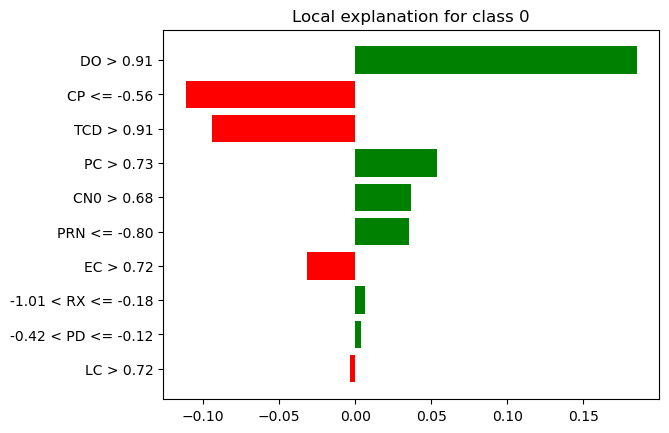

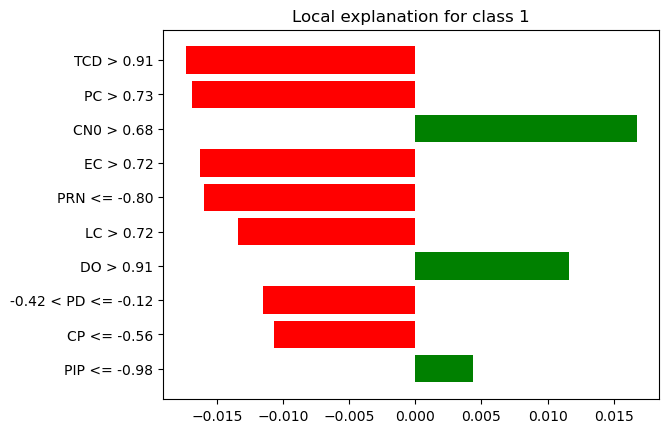

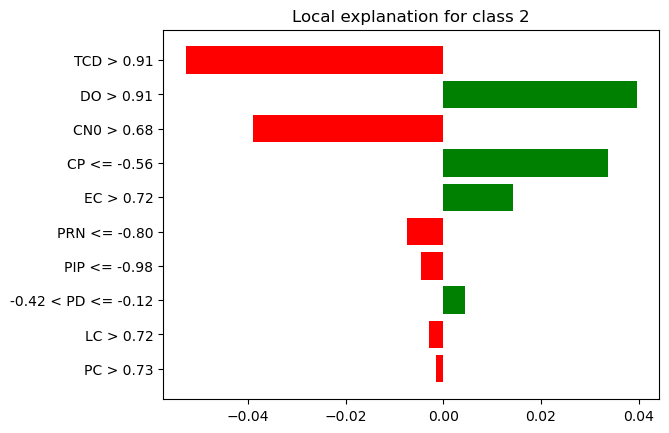

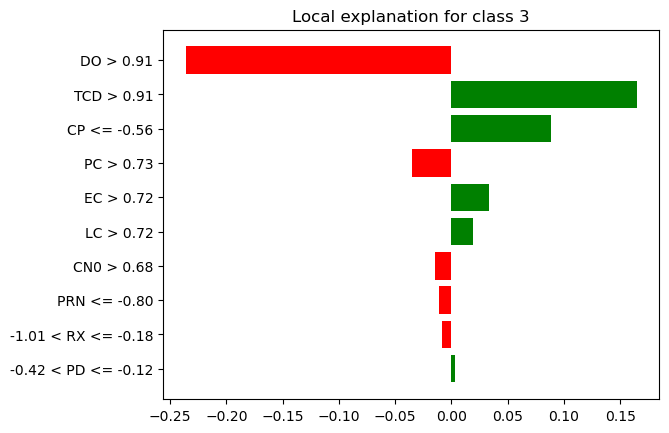

In [18]:
explainer = LimeTabularExplainer(
    training_data=X_train_scaled,
    training_labels=y_train,
    feature_names=feature_names,
    class_names=['0', '1', '2', '3'],
    kernel_width=3,
    verbose=True,
    mode='classification'
)
instance = X_test_scaled[0]
exp = explainer.explain_instance(instance, clf.predict_proba, top_labels=4)
for class_idx, class_name in enumerate(['0', '1', '2', '3']):
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.show()
    fig.savefig(f"lime_explanation_{class_name}.png")
    plt.close(fig)

In [19]:
for feature, weight in exp.as_list():
    print(f"{feature}: {weight:.4f}")

TCD > 0.91: -0.0173
PC > 0.73: -0.0168
CN0 > 0.68: 0.0167
EC > 0.72: -0.0163
PRN <= -0.80: -0.0160
LC > 0.72: -0.0134
DO > 0.91: 0.0116
-0.42 < PD <= -0.12: -0.0115
CP <= -0.56: -0.0107
PIP <= -0.98: 0.0043


In [20]:
print(y.unique())

[0 1 2 3]


Beeswarm for class 0 (Benign)


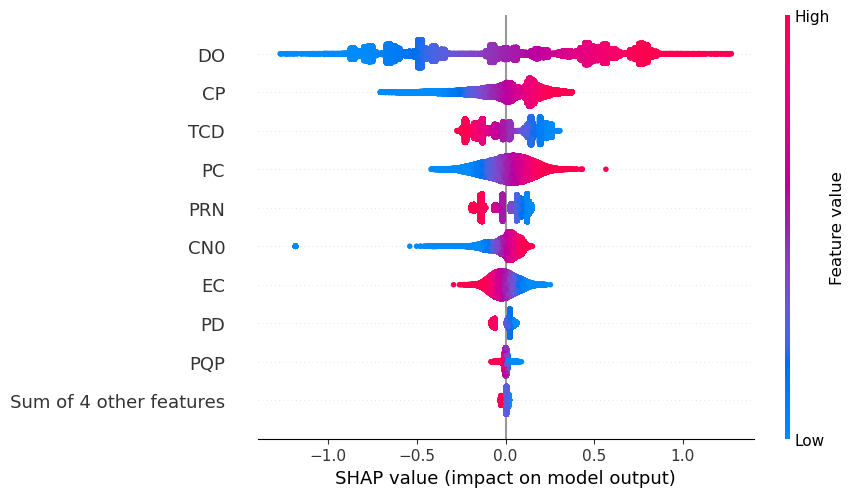

Beeswarm for class 1 (Attack 1)


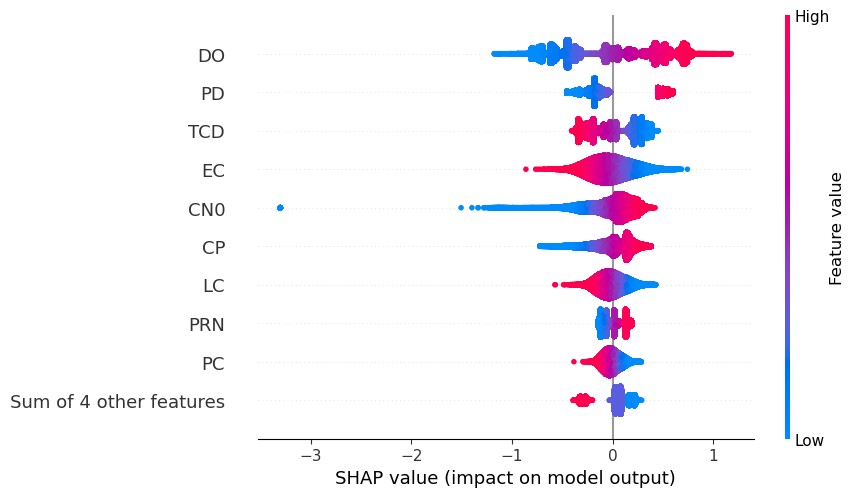

Beeswarm for class 2 (Attack 2)


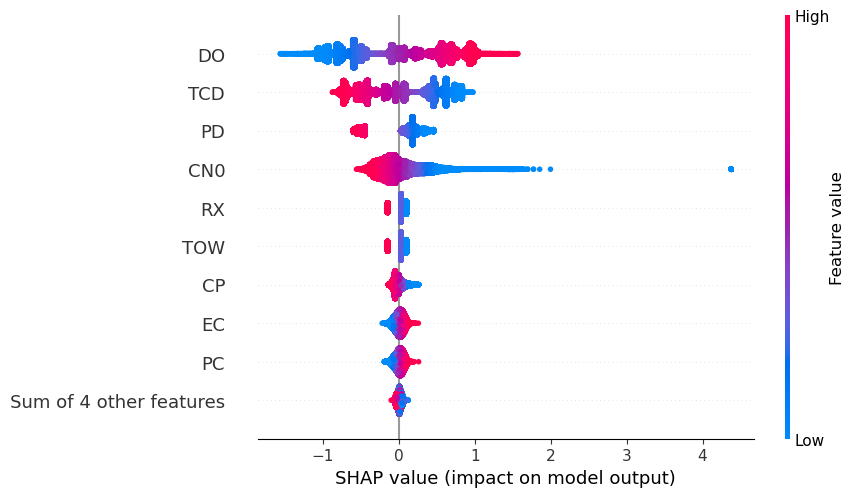

Beeswarm for class 3 (Attack 3)


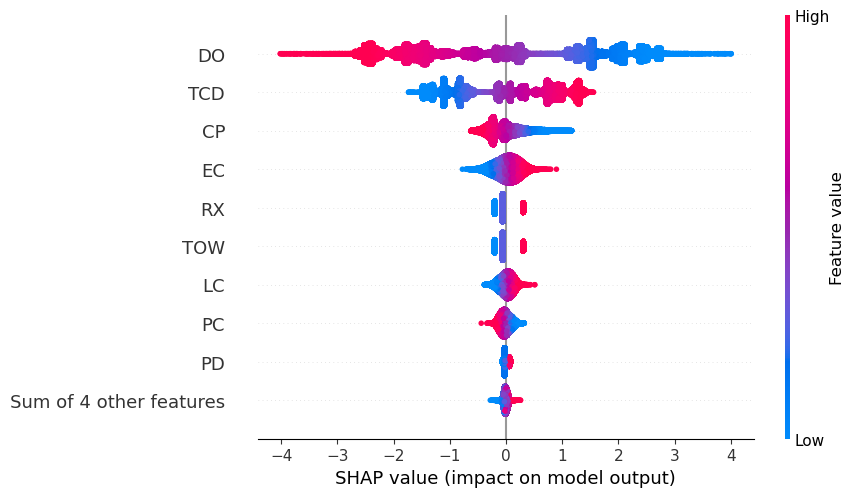

In [21]:
shap.initjs()

# Use SHAP's general Explainer
shap_explainer = shap.Explainer(clf, X_train_scaled, feature_names=feature_names)
shap_values = shap_explainer(X_test_scaled)

class_labels = {
    0: "Benign",
    1: "Attack 1",
    2: "Attack 2",
    3: "Attack 3"
}

for class_idx, class_label in enumerate(clf.classes_):
    print(f"Beeswarm for class {class_label} ({class_labels[class_label]})")
    shap.plots.beeswarm(shap_values[:, :, class_idx])